# ARIEL Lynx Arm

### How does the ARIEL Lynx Arm module work?

This module handles the physical simulation of the Lynx robot arm using the MuJoCo physics engine. It provides a testing ground for robotic manipulator behavior and integration with ARIEL's other capabilities.

In this demonstration, the environment utilizes a `TableWorld` scene instead of a standard flat world, presenting a more realistic workspace for a manipulator arm. A sine controller drives all robot actuators at each simulation step (a random controller is defined too).

This file demonstrates the process of building the arm on the table, adding a camera, driving the actuators with the sine controller, and rendering one frame after 500 simulation steps.

The implementation of the Lynxmotion robot arm into ARIEL is still work in progress. But this file serves as a first step into the showcase of how to work with it.

In [1]:
# Rendering first: it chooses the OpenGL backend before MuJoCo loads
from ariel.rendering import single_frame_renderer

# Third-party libraries
import mujoco
import numpy as np

# Local libraries
from ariel.body_phenotypes.lynx_mjspec.lynx_arm import LynxArm
from ariel.body_phenotypes.lynx_mjspec.table import TableWorld

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

#### Define the Random Controller

In [2]:
def random_controller(model, data) -> None:
    # Generate random actions
    # Action range: (-pi/2, pi/2)

    data.ctrl[:] = np.random.uniform(
        (-np.pi) / 2,
        (np.pi) / 2,
        size=model.nu,
    )
def sine_controller(model, data) -> None:
    # Set the amplitude to match your previous range: (-pi/2, pi/2)
    amplitude = np.pi / 2

    # Set how fast the arm moves (in Hertz)
    frequency = 1.0

    # Calculate the sine wave value based on the current simulation time
    action = amplitude * np.sin(2 * np.pi * frequency * data.time)

    # Apply the action to all actuators
    data.ctrl[:] = action

#### Main Simulation Runner

DoF (model.nv): 6, Actuators (model.nu): 6


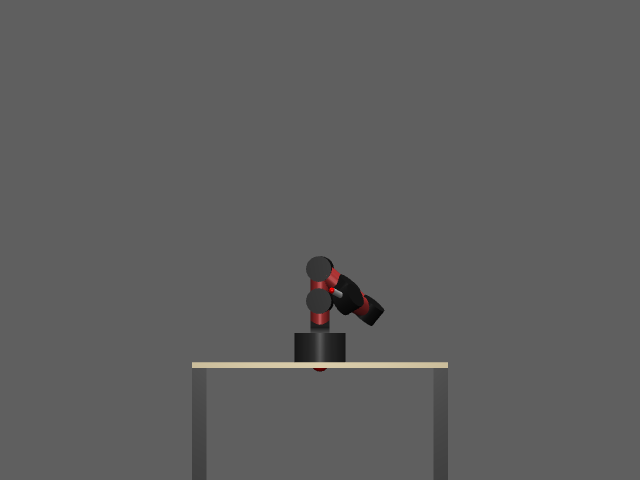

In [3]:
def run(steps: int = 500):
    """Put a default Lynx arm on the table, move it and render one frame."""
    world = TableWorld()  # Use the table world instead of the simple flat world
    arm = LynxArm()
    world.spawn(arm.spec)

    # single_frame_renderer looks through a camera named "ortho-cam"; the
    # ARIEL worlds have one, the table scene gets one here, facing the arm
    world.spec.worldbody.add_camera(
        name="ortho-cam",
        proj=mujoco.mjtProjection.mjPROJ_ORTHOGRAPHIC,
        pos=[2.0, 0.0, 1.0],
        xyaxes=[0, 1, 0, 0, 0, 1],
        fovy=1.5,  # orthographic: the frame is 1.5 m tall
    )

    model = world.compile()
    data = mujoco.MjData(model)
    print(f"DoF (model.nv): {model.nv}, Actuators (model.nu): {model.nu}")

    # The sine controller drives every actuator while the frame is simulated
    mujoco.set_mjcb_control(sine_controller)
    try:
        # TableWorld keeps MuJoCo's default 640 x 480 offscreen buffer
        return single_frame_renderer(
            model, data, steps=steps, width=640, height=480
        )
    finally:
        mujoco.set_mjcb_control(None)


run()